# 5 — Where the noise goes

**What this notebook establishes.** Exactly what our `gauss` intervention does —
which tensor, which rows, which arithmetic, at which moment in the forward pass —
and what it is worth on 8SGE. The headline is that replacing 33 rows of one
conditioning tensor with matched Gaussian noise takes the unperturbed 1 draw in 41
under 2 Å to 21 in 40. The two failure modes of the same intervention are here
too: a conditioning where it does nothing at all, and one where it turns the bond
without placing the molecule.

**What it needs.** `numpy`, `matplotlib` and this repository. No GPU, no Boltz
install, no checkpoint. One cell near the end checks this notebook's arithmetic
against the shipped implementation and needs `torch`; it skips itself when torch
is absent.

Read it after notebook 1, which establishes the failure it intervenes on, and
before notebook 3, which compares it against the published alternative.

In [1]:
import csv, sys, pathlib

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / 'src' / 'cofolding_tts').is_dir())
sys.path.insert(0, str(ROOT / 'src'))      # unneeded after `pip install -e .`

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

from cofolding_tts import basin

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9,
                     'axes.labelsize': 9, 'axes.titlesize': 9.5,
                     'xtick.labelsize': 8, 'ytick.labelsize': 8.5})
GREEN, ORANGE, GREY, BLUE, INK = '#009e73', '#d55e00', '#8a93a0', '#0072b2', '#333333'

# The shape of the thing we write to, taken from the committed inputs rather than
# asserted: one token per protein residue, one per ligand heavy atom.
seq = ''.join(l.strip() for l
              in (ROOT / 'data' / 'reference' / '8sge' / 'sequences.fasta').read_text().splitlines()
              if not l.startswith('>'))
poses = np.load(ROOT / 'data' / 'poses' / '8sge_poses.npz', allow_pickle=True)
N_PROT, N_LIG = len(seq), poses['crystal'].shape[0]
N_CHAN = 384                      # Boltz-2's token channel width, from the run logs
LO, HI = N_PROT, N_PROT + N_LIG

print(f's_trunk is (1, {N_PROT + N_LIG}, {N_CHAN}) for 8SGE')
print(f'the intervention writes rows {LO}:{HI} of it — {N_LIG} ligand rows, '
      f'{N_LIG * N_CHAN} numbers')

s_trunk is (1, 395, 384) for 8SGE
the intervention writes rows 362:395 of it — 33 ligand rows, 12672 numbers


## Where Boltz-2 is interrupted

Boltz-2 runs a **trunk** and then a **diffusion module**. The trunk embeds the
inputs and runs the pairformer over them; it emits a single representation
`s_trunk`, one row per token, and a pair representation `z_trunk`. The diffusion
module then denoises coordinates for 200 steps, conditioned on both.

Our intervention is one write, at the hand-off. `AtomDiffusion.sample` is
patched: before the original is called, the ligand rows of its `s_trunk` argument
are replaced. That happens **once**, before the first denoising step, and the
replacement is then re-read at every one of the 200 steps — nothing is refreshed
along the way. The protein rows are left exactly as the trunk produced them,
which is why the fold does not move and only the ligand does.

What the `sample` hook does **not** reach is `z_trunk`'s descendants. Boltz-2
turns `z_trunk` into five tensors before calling `sample()`, so a z perturbation
has to be installed earlier (`--hook conditioning`, or `both`). Every arm in this
notebook is `s_lig` through the `sample` hook, which is complete for `s_trunk`
except for one thing worth naming: `s_trunk` also reaches the conditioning module,
so even for s this hook is the diffusion-side write, not every use of the tensor.

wrote results/figures/nb05_hook.png


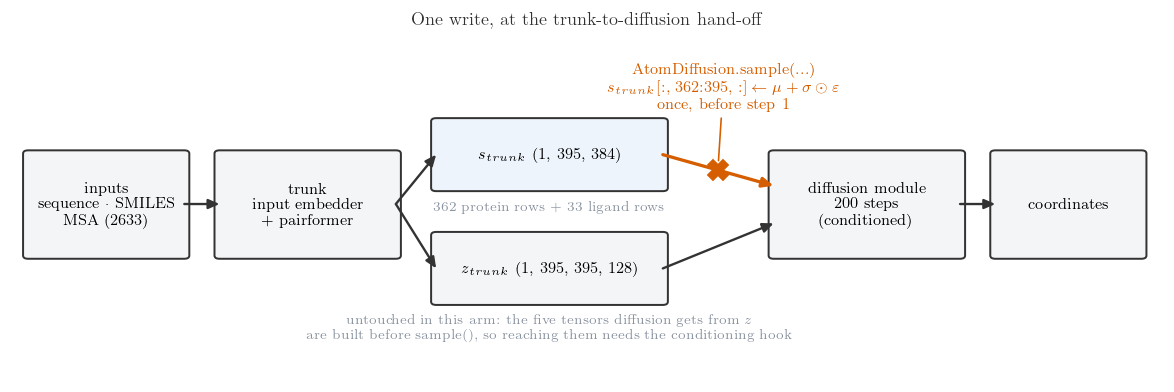

In [2]:
fig, ax = plt.subplots(figsize=(11.4, 3.5), dpi=130)
ax.set_xlim(0, 11.4); ax.set_ylim(0, 3.2); ax.axis('off')


def box(x, y, w, h, text, fc='#f4f5f7', ec=INK, fs=8.5, **kw):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.05',
                                fc=fc, ec=ec, lw=1.1, mutation_aspect=0.6))
    ax.text(x + w / 2, y + h / 2, text, ha='center', va='center', fontsize=fs, **kw)


def arrow(x0, y0, x1, y1, color=INK, lw=1.3, ls='-'):
    ax.annotate('', (x1, y1), (x0, y0),
                arrowprops=dict(arrowstyle='-|>,head_width=0.22,head_length=0.5',
                                color=color, lw=lw, ls=ls, shrinkA=0, shrinkB=0))


box(0.15, 1.15, 1.55, 0.95, 'inputs\nsequence · SMILES\nMSA (2633)')
box(2.05, 1.15, 1.75, 0.95, 'trunk\ninput embedder\n+ pairformer')
box(4.20, 1.78, 2.25, 0.62, f'$s_{{trunk}}$  (1, {N_PROT + N_LIG}, {N_CHAN})', fc='#eef4fb')
box(4.20, 0.72, 2.25, 0.62, f'$z_{{trunk}}$  (1, {N_PROT + N_LIG}, {N_PROT + N_LIG}, 128)')
box(7.55, 1.15, 1.85, 0.95, 'diffusion module\n200 steps\n(conditioned)')
box(9.75, 1.15, 1.45, 0.95, 'coordinates')

arrow(1.70, 1.63, 2.05, 1.63)
arrow(3.80, 1.63, 4.20, 2.09)
arrow(3.80, 1.63, 4.20, 1.03)
arrow(6.45, 2.09, 7.55, 1.80, color=ORANGE, lw=1.8)
arrow(6.45, 1.03, 7.55, 1.45)
arrow(9.40, 1.63, 9.75, 1.63)

# the hook, on the s_trunk -> sample() edge only
ax.plot([7.00], [1.945], marker='X', ms=11, color=ORANGE, zorder=5)
ax.annotate('AtomDiffusion.sample(...)\n'
            r'$s_{trunk}[:,\,%d{:}%d,\,:] \leftarrow \mu + \sigma \odot \varepsilon$'
            % (LO, HI) + '\nonce, before step 1',
            xy=(7.00, 2.00), xytext=(7.05, 2.95), ha='center', va='top',
            fontsize=8.5, color=ORANGE,
            arrowprops=dict(arrowstyle='-', color=ORANGE, lw=0.9))
ax.text(5.32, 1.66, f'{N_PROT} protein rows + {N_LIG} ligand rows',
        ha='center', va='top', fontsize=7.5, color=GREY)
ax.text(5.32, 0.60, 'untouched in this arm: the five tensors diffusion gets from $z$\n'
                    'are built before sample(), so reaching them needs the conditioning hook',
        ha='center', va='top', fontsize=7.5, color=GREY)
ax.set_title('One write, at the trunk-to-diffusion hand-off', fontsize=10, color=INK)
out = ROOT / 'results' / 'figures' / 'nb05_hook.png'
fig.savefig(out, bbox_inches='tight')
print('wrote', out.relative_to(ROOT))

## The block, and what replaces it

Write the slice as `s_lig = s_trunk[:, 362:395, :]`, a (1, 33, 384) block: one row
per ligand heavy atom, 384 channels each. Two statistics are taken over it, both
**per channel, down the 33 rows**:

$$\mu_c = \frac{1}{33}\sum_t s_{tc}, \qquad
  \sigma_c = \mathrm{SD}_t\,[\,s_{tc}\,]$$

and every row is then thrown away and redrawn from them:

$$s^{\,\mathrm{new}}_{tc} = \mu_c + \sigma_c\,\varepsilon_{tc},
  \qquad \varepsilon \sim \mathcal{N}(0, 1)$$

So the channel statistics of the block survive and **which token owns which row
does not**. Decomposing a row as `s[t, c] = mu[c] + r[t, c]`, the intervention
keeps `mu` and the per-channel spread and destroys the token-varying residual `r`.

`mean` and `shuffle` exist to separate those two things: `mean` makes every row
`mu` with no noise drawn at all, and `shuffle` permutes the real rows, so the
block stays one the trunk actually produced while ownership is just as destroyed.

wrote results/figures/nb05_block.png


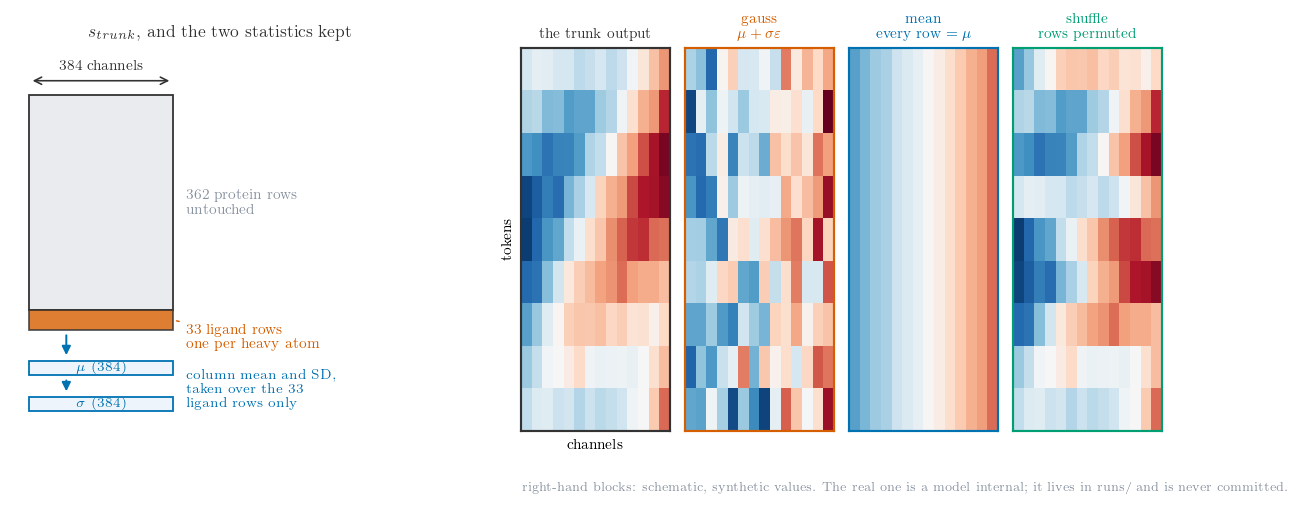

In [3]:
fig = plt.figure(figsize=(11.4, 3.9), dpi=130)
gs = fig.add_gridspec(1, 2, width_ratios=[1.0, 1.55], wspace=0.18)

# --- left: the tensor, and where mu and sigma come from ------------------------
ax = fig.add_subplot(gs[0]); ax.axis('off')
ax.set_xlim(0, 1.55); ax.set_ylim(0, 1.06)
X0, X1 = 0.06, 0.60                                   # the block's channel extent
TOP, BOT = 0.93, 0.28                                 # and its token extent
h_lig = (TOP - BOT) * N_LIG / (N_PROT + N_LIG)
ax.add_patch(Rectangle((X0, BOT + h_lig), X1 - X0, TOP - BOT - h_lig,
                       fc='#e9ebee', ec=INK, lw=1.0))
ax.add_patch(Rectangle((X0, BOT), X1 - X0, h_lig, fc=ORANGE, ec=INK, lw=1.0, alpha=0.8))
ax.annotate('', (X0, 0.97), (X1, 0.97), arrowprops=dict(arrowstyle='<->', color=INK, lw=0.9))
ax.text((X0 + X1) / 2, 1.00, f'{N_CHAN} channels', ha='center', fontsize=8, color=INK)
ax.text(X1 + 0.05, (TOP + BOT + h_lig) / 2, f'{N_PROT} protein rows\nuntouched',
        va='center', fontsize=8, color=GREY)
ax.annotate(f'{N_LIG} ligand rows\none per heavy atom', xy=(X1, BOT + h_lig / 2),
            xytext=(X1 + 0.05, BOT - 0.02), va='center', fontsize=8, color=ORANGE,
            arrowprops=dict(arrowstyle='-', color=ORANGE, lw=0.8))
for lab, y in (('$\\mu$   (384)', 0.155), ('$\\sigma$   (384)', 0.055)):
    ax.add_patch(Rectangle((X0, y), X1 - X0, 0.04, fc='#eef4fb', ec=BLUE, lw=1.0))
    ax.text((X0 + X1) / 2, y + 0.020, lab, ha='center', va='center', fontsize=7.5, color=BLUE)
ax.annotate('', (0.20, 0.200), (0.20, BOT - 0.005),
            arrowprops=dict(arrowstyle='-|>', color=BLUE, lw=1.1))
ax.annotate('', (0.20, 0.100), (0.20, 0.150), arrowprops=dict(arrowstyle='-|>', color=BLUE, lw=1.1))
ax.text(X1 + 0.05, 0.115, 'column mean and SD,\ntaken over the 33\nligand rows only',
        va='center', fontsize=7.5, color=BLUE)
ax.set_title('$s_{trunk}$, and the two statistics kept', fontsize=9.5, color=INK)

# --- right: the three destructive arms, as pictures ---------------------------
rng = np.random.default_rng(7)
mu_c = np.linspace(-1.1, 1.1, 14)
blk = (mu_c + 0.75 * np.cos(np.arange(9)[:, None] * 0.8 + np.arange(14) * 0.35)
       + 0.12 * rng.standard_normal((9, 14)))
mu_b, sd_b = blk.mean(0, keepdims=True), blk.std(0, ddof=1, keepdims=True)
perm = rng.permutation(9)
panels = [('the trunk output', blk, INK),
          ('gauss\n$\\mu + \\sigma\\varepsilon$', mu_b + sd_b * rng.standard_normal(blk.shape), ORANGE),
          ('mean\nevery row $= \\mu$', np.repeat(mu_b, 9, 0), BLUE),
          ('shuffle\nrows permuted', blk[perm], GREEN)]
sub = gs[1].subgridspec(1, 4, wspace=0.10)
lim = max(np.abs(b).max() for _, b, _ in panels)
for i, (title, b, colour) in enumerate(panels):
    bx = fig.add_subplot(sub[i])
    bx.imshow(b, cmap='RdBu_r', vmin=-lim, vmax=lim, aspect='auto', interpolation='nearest')
    bx.set_title(title, fontsize=8, color=colour)
    bx.set_xticks([]); bx.set_yticks([])
    for s in bx.spines.values():
        s.set_edgecolor(colour); s.set_linewidth(1.2)
    if i == 0:
        bx.set_ylabel('tokens', fontsize=8); bx.set_xlabel('channels', fontsize=8)
fig.text(0.985, 0.005, 'right-hand blocks: schematic, synthetic values. The real one is a '
                       'model internal; it lives in runs/ and is never committed.',
         ha='right', fontsize=7, color=GREY)
out = ROOT / 'results' / 'figures' / 'nb05_block.png'
fig.savefig(out, bbox_inches='tight')
print('wrote', out.relative_to(ROOT))

## The arithmetic, in four lines

Below is the whole intervention, in numpy, on a stand-in block of the real shape.
The stand-in matters for honesty: the real `s_lig` is a raw model internal — 12,672
numbers that mean nothing outside the run that produced them — and it belongs in
`runs/`; nothing in this repository commits one. What is demonstrated here is therefore the *operation*, not the data
it was applied to, and the last cell of the notebook checks that this numpy
version is the same arithmetic the shipped hook performs.

The stand-in is built the way the decomposition `s[t, c] = mu[c] + r[t, c]`
describes: a per-channel offset every row shares, plus a genuinely token-varying
part. Four things to read off the output:

- the per-channel mean and spread are preserved **in expectation only** — with 33
  rows the realised column mean of the replacement sits about $\sigma/\sqrt{33}$
  away from $\mu$. `shuffle` is the arm that preserves them exactly;
- the token-varying part is **gone**, which is the point. It is gone by
  construction and not by luck: $\varepsilon$ is drawn independently per element,
  so no two replacement rows can agree on anything but $\mu$ and $\sigma$;
- the block's rank goes with it. The stand-in's residual is two components; the
  replacement spreads the same variance over all 33;
- the Frobenius norm barely moves, so this is not a magnitude change dressed up as
  an ablation. The *difference* between old and new is large, as it must be — this
  is a different block of the same size, not a nudge. The run log records
  `base_norm`, `new_norm` and `delta_norm` for every write, so all of this is
  checkable per draw rather than taken on trust.

In [4]:
rng = np.random.default_rng(0)
offset = rng.normal(0, 1, N_CHAN)                       # mu[c]: shared by every row
load = rng.normal(0, 1, (N_LIG, 2))                     # r[t, c]: two token-varying
factor = rng.normal(0, 1, (2, N_CHAN))                  #   factors, loaded per token
block = offset + 0.5 * load @ factor + 0.1 * rng.standard_normal((N_LIG, N_CHAN))

mu = block.mean(axis=0, keepdims=True)                  # (1, 384)
sd = block.std(axis=0, ddof=1, keepdims=True)           # unbiased, as torch.std is
eps = np.random.default_rng(12345).standard_normal(block.shape)
new = mu + sd * eps                                     # <- the whole of `gauss`


def residual_corr(b):
    # how much the token-varying parts of two rows resemble each other, on average
    r = b - b.mean(axis=0, keepdims=True)
    c = np.corrcoef(r)
    return np.abs(c[~np.eye(len(c), dtype=bool)]).mean()


def top2_share(b):
    # how much of the token-varying variance the two leading components carry
    s = np.linalg.svd(b - b.mean(axis=0, keepdims=True), compute_uv=False)
    return float((s[:2] ** 2).sum() / (s ** 2).sum())


print(f'block {block.shape}, a stand-in for s_trunk[:, {LO}:{HI}, :]')
print(f'  per-channel mean    |new - mu| / sigma  = {np.abs(new.mean(0) - mu[0]).mean() / sd.mean():.3f}'
      f'   (expected ~1/sqrt({N_LIG}) = {1 / np.sqrt(N_LIG):.3f})')
print(f'  per-channel spread  new SD / old SD     = {(new.std(0, ddof=1) / sd[0]).mean():.3f}')
print(f'  token-varying part  mean |row corr|     = {residual_corr(block):.3f} before, '
      f'{residual_corr(new):.3f} after')
print(f'                      top 2 components   = {top2_share(block):.1%} of it before, '
      f'{top2_share(new):.1%} after')
print(f'  Frobenius norm                          = {np.linalg.norm(block):.1f} before, '
      f'{np.linalg.norm(new):.1f} after,  |new - old| = {np.linalg.norm(new - block):.1f}')

block (33, 384), a stand-in for s_trunk[:, 362:395, :]
  per-channel mean    |new - mu| / sigma  = 0.137   (expected ~1/sqrt(33) = 0.174)
  per-channel spread  new SD / old SD     = 0.994
  token-varying part  mean |row corr|     = 0.616 before, 0.063 after
                      top 2 components   = 98.1% of it before, 12.6% after
  Frobenius norm                          = 137.1 before, 136.6 after,  |new - old| = 109.4


## What it is worth on 8SGE

Five conditionings, one per model seed, 40 `gauss` draws each, and the unperturbed
`control` at seed 42. Within a conditioning the model seed is held fixed and only
the **direction seed** moves, so each `gauss` row is one trunk output perturbed 40
different ways — the same block, 40 replacements for it.

Scoring is `cofolding_tts.basin`: within 40° of a measured basin centre and nearer
to that one than the other, with anything else counted as **neither** rather than
folded into a rate. Both columns are reported because they disagree, and the
disagreement is the most useful thing in the table.

In [5]:
ARMS = [('control', 42, 'unperturbed'),
        ('gauss-s_lig-s05', 5, 'gauss'),
        ('gauss-s_lig-s14', 14, 'gauss'),
        ('gauss-s_lig', 42, 'gauss'),
        ('gauss-s_lig-s59', 59, 'gauss'),
        ('gauss-s_lig-s12', 12, 'gauss')]

rows = list(csv.DictReader((ROOT / 'results' / '8sge_per_pose.csv').open()))
arm = {}
for name, seed, kind in ARMS:
    sel = [r for r in rows if r['arm'] == name]
    arm[name] = {'seed': seed, 'kind': kind,
                 'rmsd': np.array([float(r['ligand_rmsd_angstrom']) for r in sel]),
                 'tors': np.array([float(r['axial_torsion_deg']) for r in sel])}

print(f"{'arm':>16} {'model seed':>10} {'n':>4} {'crystal basin':>14} "
      f"{'under 2 A':>10} {'median RMSD':>12}")
for name, _, _ in ARMS:
    d = arm[name]
    n = basin.counts(d['tors'])
    print(f"{name:>16} {d['seed']:>10} {len(d['rmsd']):>4} "
          f"{n['correct']:>8}/{len(d['tors']):<5} {int((d['rmsd'] < 2).sum()):>10} "
          f"{np.median(d['rmsd']):>10.2f} A")
print(f"\nbasin centres, measured over 260 poses: {basin.CORRECT_CENTRE:+.1f} deg "
      f"(crystal) and {basin.WRONG_CENTRE:+.1f} deg (the model's)")

             arm model seed    n  crystal basin  under 2 A  median RMSD
         control         42   41        1/41             1       6.77 A
 gauss-s_lig-s05          5   40        0/40             0       6.88 A
 gauss-s_lig-s14         14   40       37/40             1       2.98 A
     gauss-s_lig         42   40       21/40            21       1.61 A
 gauss-s_lig-s59         59   40       21/40            21       1.26 A
 gauss-s_lig-s12         12   40       24/40            24       1.68 A

basin centres, measured over 260 poses: -112.6 deg (crystal) and +68.7 deg (the model's)


## Three outcomes, not one

- **Seeds 42, 59 and 12 are the rescue.** 21, 21 and 24 draws of 40 come in under
  2 Å, against 1 of 41 unperturbed, and the correct-basin median is around 1.3–1.7 Å.
  Destroying those 33 rows frees the axial choice, and the direction seed then
  decides it — roughly a coin flip.
- **Seed 5 does nothing.** 0 of 40 in the crystal basin. The same write, the same
  arm, a different trunk output: whatever holds this conditioning in the wrong
  basin is not carried by `s_lig` alone.
- **Seed 14 turns the bond without placing the molecule.** 37 of 40 reach the
  crystal basin and 1 of 40 lands under 2 Å, median 2.98 Å. The order parameter is
  **necessary, not sufficient**: a correct torsion in a shifted pose is not a
  rescue, and an arm scored on the basin alone would have read as the best of the
  five.

That is why both columns are printed, and why `basin.classify` keeps a `neither`
class instead of splitting every pose between two rates.

wrote results/figures/nb05_arms.png


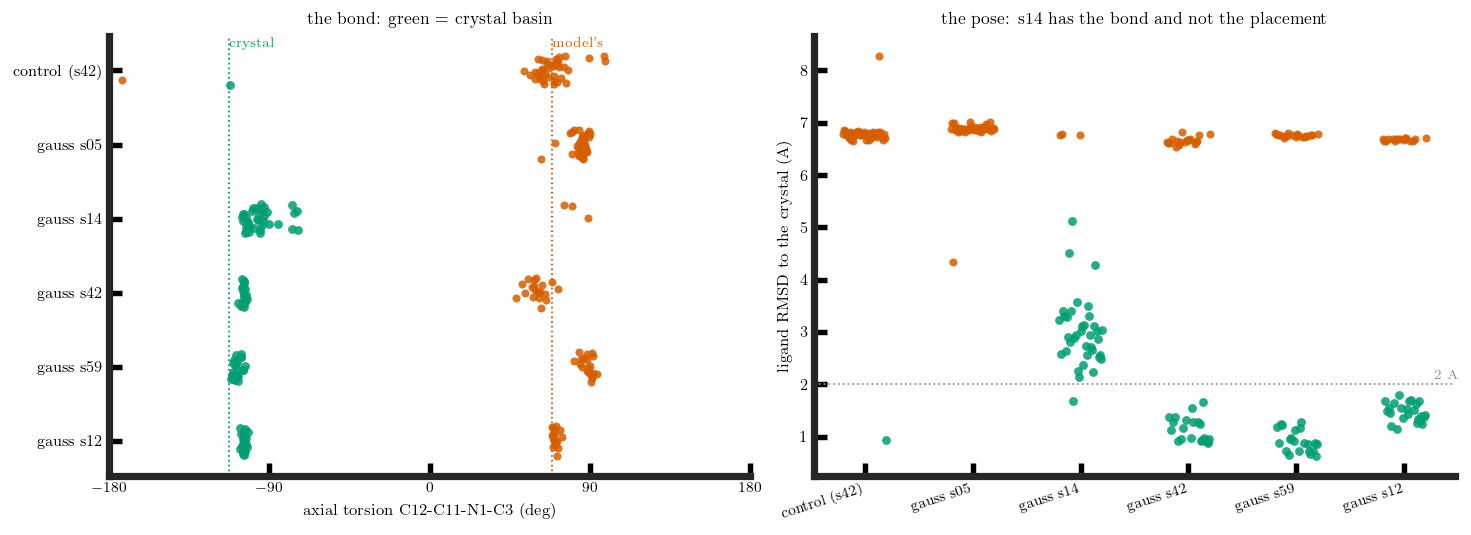

In [6]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(11.2, 4.0), dpi=130, constrained_layout=True)
order = [n for n, _, _ in ARMS]
label = {'control': 'control (s42)', 'gauss-s_lig-s05': 'gauss s05',
         'gauss-s_lig-s14': 'gauss s14', 'gauss-s_lig': 'gauss s42',
         'gauss-s_lig-s59': 'gauss s59', 'gauss-s_lig-s12': 'gauss s12'}

for i, name in enumerate(order):
    d = arm[name]
    lab = basin.classify(d['tors'])
    jit = np.linspace(-0.2, 0.2, len(d['tors']))
    for sel, colour, size in ((lab == 'correct', GREEN, 24), (lab != 'correct', ORANGE, 20)):
        ax.scatter(d['tors'][sel], i + jit[sel], s=size, color=colour, alpha=0.85,
                   linewidths=0)
        bx.scatter(i + jit[sel], d['rmsd'][sel], s=size, color=colour, alpha=0.85,
                   linewidths=0)
for centre, colour, name in ((basin.CORRECT_CENTRE, GREEN, 'crystal'),
                             (basin.WRONG_CENTRE, ORANGE, "model's")):
    ax.axvline(centre, color=colour, lw=1.0, ls=':')
    ax.annotate(f' {name}', xy=(centre, 0.995), xycoords=('data', 'axes fraction'),
                color=colour, fontsize=7.5, va='top', ha='left')
ax.set_yticks(range(len(order))); ax.set_yticklabels([label[n] for n in order])
ax.set_xlim(-180, 180); ax.set_xticks([-180, -90, 0, 90, 180])
ax.set_xlabel('axial torsion C12-C11-N1-C3 (deg)')
ax.set_title('the bond: green = crystal basin', fontsize=9.5)
ax.invert_yaxis()

bx.axhline(2.0, color=GREY, lw=1.0, ls=':')
bx.text(len(order) - 0.5, 2.1, '2 A', color=GREY, fontsize=7.5, ha='right')
bx.set_xticks(range(len(order)))
bx.set_xticklabels([label[n] for n in order], rotation=18, ha='right')
bx.set_ylabel('ligand RMSD to the crystal (A)')
bx.set_title('the pose: s14 has the bond and not the placement', fontsize=9.5)
for a in (ax, bx):
    a.spines[['top', 'right']].set_visible(False)
out = ROOT / 'results' / 'figures' / 'nb05_arms.png'
fig.savefig(out, bbox_inches='tight')
print('wrote', out.relative_to(ROOT))

## The same cell, pointed at the other arms

`gauss` is one of five things the hook can write, and the others are controls
rather than alternatives. All of them act on the same slice at the same moment.

| `--intervention` | what it writes | what it controls for |
| --- | --- | --- |
| `gauss` | $\mu + \sigma\varepsilon$, a fresh draw per element | the arm above |
| `mean` | every row $= \mu$, no RNG at all | that the result is not an artifact of the particular noise drawn |
| `shuffle` | the real rows, permuted | that the *information* was lost rather than the representation's form broken: mean, SD, norm and rank are all preserved exactly |
| `additive` | $s + \lambda\sigma\varepsilon$ | the original signal survives, buried — the only arm for which `--lam` means anything |
| `lerp` | $\mu + \lambda(s - \mu) + \sqrt{1-\lambda^2}\,\sigma\varepsilon$ | the variance-preserving path from the trunk's own block ($\lambda=1$) to `gauss` ($\lambda=0$), with no change of scale along it |

`--regions` chooses the slice the same way: `s_prot` for the protein rows, `s_lig`
for the ligand rows, `s_atoms` for named ligand tokens, `z_pl` for the
protein-ligand pair block, and so on. `docs/method.md` carries the rest.

In [7]:
# Does this notebook's arithmetic match the shipped hook? Needs torch, so it is
# the one cell here that belongs to the reproduce tier.
try:
    import torch
    from cofolding_tts.intervene import channel_moments, direction_seed
except Exception as exc:                                    # no torch in a bare clone
    print('skipped — needs the reproduce environment:', type(exc).__name__, exc)
else:
    sub = torch.from_numpy(block).unsqueeze(0)              # (1, 33, 384), as the hook sees it
    mu_t, sd_t = channel_moments(sub)
    seed = direction_seed(1, 's_lig', False)                # --direction-seed 1, region s_lig
    gen = torch.Generator(device='cpu').manual_seed(seed)
    eps_t = torch.randn(sub.shape, generator=gen, dtype=torch.float32)
    shipped = (mu_t + sd_t * eps_t).numpy()[0]
    mine = mu + sd * eps_t.numpy()[0]                       # same eps, this notebook's mu/sd

    print(f'direction seed for draw 1, region s_lig : {seed}')
    print(f'max |mu_shipped - mu_here|              : {np.abs(mu_t.numpy()[0] - mu).max():.2e}')
    print(f'max |sd_shipped - sd_here|              : {np.abs(sd_t.numpy()[0] - sd).max():.2e}')
    print(f'max |block_shipped - block_here|        : {np.abs(shipped - mine).max():.2e}')
    assert np.abs(shipped - mine).max() < 1e-4, 'the notebook and the hook disagree'
    print('\nsame arithmetic (the residual is float32 against float64, nothing else)')

direction seed for draw 1, region s_lig : 1294575339
max |mu_shipped - mu_here|              : 2.97e-07
max |sd_shipped - sd_here|              : 7.36e-08
max |block_shipped - block_here|        : 5.19e-07

same arithmetic (the residual is float32 against float64, nothing else)


## Reproducing it, and the two seeds

```bash
bash scripts/setup_boltz.sh                    # a separate venv with boltz==2.2.1
export BOLTZ_CHECKPOINT=/path/to/boltz2_conf.ckpt
export BOLTZ_CACHE=/path/to/boltz/cache

python scripts/run_8sge.py --arm control --draws 41 --seed 42
python scripts/run_8sge.py --arm gauss   --draws 40 --seed 42     # and 5, 12, 14, 59
python scripts/score_8sge.py --runs runs
```

`run_8sge.py --arm gauss` is `intervene.py --regions s_lig --intervention gauss
--direction-seed <draw>`, one process per draw, about 255 s each on one GPU.

The **two seeds are independent, and that is the whole design**. `--seed` is the
model seed: it fixes the MSA subsample and everything the trunk does, so holding
it across an arm is what makes 40 draws comparable. `--direction-seed` fixes
$\varepsilon$ and is derived from the seed and the region name alone, so draw 7
of one conditioning and draw 7 of another get the same $\varepsilon$ and can be
compared one to one.

## What this is not

- **Not a method.** Destroying a conditioning tensor helps on a system the model
  gets wrong. Notebook 3's last section carries the cost: on 8JJQ, which the model
  already gets right 18 times in 20, this arm takes it to 27 of 40.
- **Not steering.** There is no objective, no ranking and no reference in the
  loop. The direction seed decides the outcome and nothing here picks a draw —
  which is the gap between this and a usable test-time procedure.
- **Not a mechanism for the 0-of-40 case.** Seed 5 says `s_lig` is not the only
  thing holding the wrong basin, and what else does is open.
- **One system, one model.** 8SGE under Boltz-2 2.2.1.